In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from matplotlib import pyplot as plt

from environments.implementations.qm_env_lindblad import Lindblad_Environment
from environments.implementations.qm_env_montecarlo import MonteCarlo_Environment

In [ ]:
LAMBDA_C = 0.15      #<---output by RL SAC in future

Nb = 6

ENV_PARAMS = {
    #general
    "wc": 1.0,
    "wb": 1.0,

    "Nc": 6,
    "Nb": Nb,

    "kappa": 0.2,
    
    "dt": 0.05,
    "tau": 10.0,

    #for monte carlo
    "ntraj": 16,
    "seed": 42,

    #for SSE

    #for SAC
    "min_u": -0.3,
    "max_u": 0.3,
    "objective": "ergotropy_full",
    "reward_coeff": 1.0
}

In [ ]:
def run(env, u):

    history = []

    terminated = False

    while not terminated:
        
        result, terminated = env.step(u)
        history.append(result)

    return history

In [ ]:
lindblad_history = run(
    Lindblad_Environment(ENV_PARAMS), 
    LAMBDA_C
)

montecarlo_history = run(
    MonteCarlo_Environment(ENV_PARAMS), 
    LAMBDA_C
)


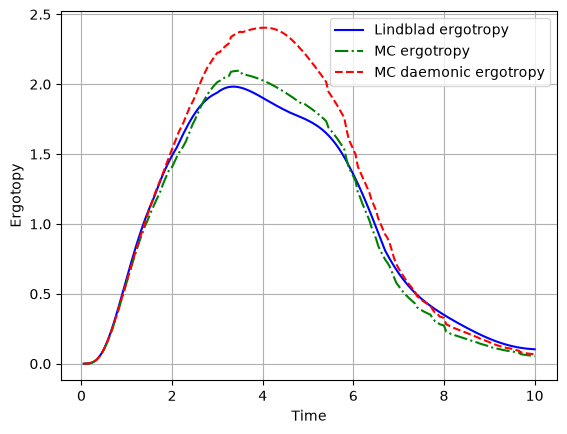

In [4]:
key = "ergotropy_full"

plt.plot(
    [h["time"] for h in lindblad_history], 
    [h[key] for h in lindblad_history],
    c = "blue",
    label = "Lindblad ergotropy"
)

plt.plot(
    [h["time"] for h in montecarlo_history], 
    [h[key] for h in montecarlo_history],
    c = "green",
    ls = "-.",
    label = "MC ergotropy"
)

plt.plot(
    [h["time"] for h in montecarlo_history], 
    [h["daemonic_ergotropy_full"] for h in montecarlo_history],
    c = "red",
    ls = "--",
    label = "MC daemonic ergotropy"
)  

plt.legend()
plt.grid()

plt.xlabel("Time")
plt.ylabel("Ergotopy")

plt.show()